## Imports

In [14]:
import json, pickle, random, math
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from tokenizers import Tokenizer
import time
import matplotlib.pyplot as plt
import pandas as pd
import copy
from collections import defaultdict
import random
import os


## Loading the existing preprocessed data

In [15]:
working_dir = Path.cwd().resolve()
PROJECT_DIR = working_dir.parent if working_dir.name == "notebooks" else working_dir
PROCESSED_DIR = PROJECT_DIR/"data"/"processed"
MODEL_DIR = PROJECT_DIR/"models"/"attention"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for filename in ["tokenizer.json", "encoded_lines.pkl", "vocab.json"]:
    if not (PROCESSED_DIR/filename).exists():
        raise FileNotFoundError(f"Missing {PROCESSED_DIR/filename}. Run preprocessing first.")

print("Project:", PROJECT_DIR)
print("Checkpoints:", MODEL_DIR)

Project: /home/gusvahaye@GU.GU.SE/Smart-Autocomplete-Systems
Checkpoints: /home/gusvahaye@GU.GU.SE/Smart-Autocomplete-Systems/models/attention


In [16]:
hf_tokenizer = Tokenizer.from_file(str(PROCESSED_DIR/"tokenizer.json"))

with open(PROCESSED_DIR/"encoded_lines.pkl", "rb") as f:
    encoded_lines = pickle.load(f)

with open(PROCESSED_DIR/"vocab.json", "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

word_to_id = vocab_data["word_to_id"]
id_to_word = {int(idx): word for word, idx in word_to_id.items()}

vocab_size = len(word_to_id)

bos_id = word_to_id["<bos>"]
eos_id = word_to_id["<eos>"]
unk_id = word_to_id["<unk>"]
pad_id = word_to_id["<pad>"]

---

## settings

In [17]:
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed) # python rng
    np.random.seed(seed) # numpy rng
    torch.manual_seed(seed) # pytorch rng
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BLOCK_SIZE = 32
BATCH_SIZE = 4
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 2
FF_DIM = 256
DROPOUT = 0.2
LEARNING_RATE = 0.001
EPOCHS = 10

In [18]:
device

device(type='cuda')

### creating training blocks

mostly like what we did in lstm

In [19]:
def make_transformer_dataset(sequences, block_size, pad_id):
    inputs = []
    targets = []
    
    for sequence in sequences:
        for start in range(0, len(sequence) - 1, block_size):
            # just like lstm
            end = min(start + block_size, len(sequence) - 1)
            
            x = list(sequence[start:end])
            y = list(sequence[start + 1:end + 1])
            
            inputs.append(x+[pad_id]*(block_size - len(x)))
            targets.append(y+[pad_id]*(block_size - len(y)))
            
    input_blocks = torch.tensor(inputs, dtype=torch.long)
    output_blocks = torch.tensor(targets, dtype=torch.long)
            
    return TensorDataset(input_blocks,output_blocks)

train_dataset = make_transformer_dataset(encoded_lines["train"], BLOCK_SIZE, pad_id)
validation_dataset = make_transformer_dataset(encoded_lines["validation"], BLOCK_SIZE, pad_id)
test_dataset = make_transformer_dataset(encoded_lines["test"], BLOCK_SIZE, pad_id)

print("Training blocks:", len(train_dataset))
print("Validation blocks:", len(validation_dataset))
print("Test blocks:", len(test_dataset))

def make_train_loader(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)

validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

x_example, y_example = train_dataset[0]

print("\nInput ids:", x_example[:8].tolist())
print("Target ids:", y_example[:8].tolist())

Training blocks: 70766
Validation blocks: 7386
Test blocks: 8390

Input ids: [2, 21646, 119, 3840, 152, 44, 1, 4345]
Target ids: [21646, 119, 3840, 152, 44, 1, 4345, 23]


---

## Decoder-only transformer with causal self-attention

In [20]:
class AttentionLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=2, ff_dim=256, dropout=0.2, block_size=32, pad_id=0):
        super().__init__()
        self.block_size = block_size
        self.pad_id = pad_id
        
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.position_embedding = nn.Embedding(block_size, d_model)
        
        # transformer layer
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=ff_dim, dropout=dropout, batch_first=True, norm_first=True, activation="gelu")
        
        self.transformer = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False) # stacking transformer layers
        self.final_norm = nn.LayerNorm(d_model) # normalization
        self.output = nn.Linear(d_model, vocab_size)

    def forward(self, input_ids):
        batch, length = input_ids.shape
    
        positions = torch.arange(length, device=input_ids.device).unsqueeze(0)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        
        # True means attention is blocked so future positions are invisible
        causal_mask = torch.triu(torch.ones(length, length, dtype=torch.bool, device=input_ids.device), diagonal=1)

        x = self.transformer(x, mask=causal_mask) # pass it to transformer
        return self.output(self.final_norm(x))

In [21]:
MODEL_CONFIG = {
    "vocab_size": vocab_size,
    "d_model": D_MODEL,
    "n_heads": N_HEADS,
    "n_layers": N_LAYERS,
    "ff_dim": FF_DIM,
    "dropout": DROPOUT,
    "block_size": BLOCK_SIZE,
    "pad_id": pad_id
}

model = AttentionLanguageModel(**MODEL_CONFIG).to(device)

total_params = sum(p.numel() for p in model.parameters()) # counting parameters
print("Parameters:", f"{total_params:,}")

# then to test first we have to prepare the example input
example_input = x_example.unsqueeze(0) # add one dimensioin at index 0
example_input = example_input.to(device)

print("Input shape:", example_input.shape)

# then testing the model
model.eval()
with torch.no_grad():
    output = model(example_input)

print("Output shape:", output.shape)

## checking the dimension
expected_shape = (1, BLOCK_SIZE, vocab_size)
assert output.shape == expected_shape

print("Forward-pass shape test passed")

Parameters: 12,133,717
Input shape: torch.Size([1, 32])
Output shape: torch.Size([1, 32, 46165])
Forward-pass shape test passed


---

## Training and evaluation for one full epoch

In [22]:
# Loss function
criterion = nn.CrossEntropyLoss(ignore_index=pad_id, reduction="sum")

def run_epoch(model, data_loader, criterion, optimizer=None):
    # like the way i wrote the same function for lstm, if we provide optimizer the function will be training, otherwise evaluation
    training = optimizer is not None
    model.train(training)

    total_loss = 0
    total_tokens = 0

    for inputs, targets in data_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        valid_tokens = (targets != pad_id).sum().item() # Count tokens that are not padding
        if valid_tokens == 0:
            continue

        # making prediction
        with torch.set_grad_enabled(training):
            logits = model(inputs)

            # loss
            loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))

            if training:
                optimizer.zero_grad()

                # gradients
                (loss / valid_tokens).backward()

                # to prevent very large gradients
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

                optimizer.step()

        # Save loss and token count
        total_loss += loss.item()
        total_tokens += valid_tokens

    if total_tokens == 0:
        raise ValueError("No valid tokens in DataLoader")

    average_loss = total_loss / total_tokens
    perplexity = math.exp(min(average_loss, 20))

    return {
        "loss": average_loss,
        "perplexity": perplexity,
        "tokens": total_tokens
    }


print("Training batches:", len(make_train_loader()))
print("Validation batches:", len(validation_loader))

Training batches: 17692
Validation batches: 1847


## Baseline Transformer training and checkpointing

In [23]:
set_seed(SEED)

# first creating the model and optimizer
baseline_model = AttentionLanguageModel(**MODEL_CONFIG).to(device)
optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=LEARNING_RATE)

history = []
best_ppl = float("inf")

# file paths
model_path = MODEL_DIR/"attention_baseline_best.pt"
history_path = MODEL_DIR/"attention_baseline_history.json"

# measuring total training time
if device.type == "cuda":
    torch.cuda.synchronize()

training_start = time.perf_counter()

# Training loop
for epoch in range(1, EPOCHS + 1):

    start_time = time.time()
    train_results = run_epoch(baseline_model, make_train_loader(SEED + epoch), criterion, optimizer) # we provide different seed each epoch for the training loader

    # validation model
    val_results = run_epoch(baseline_model, validation_loader, criterion)

    train_loss = train_results["loss"]
    train_ppl = train_results["perplexity"]
    val_loss = val_results["loss"]
    val_ppl = val_results["perplexity"]

    history.append({ # then we save everything for each epoch
        "epoch": epoch,
        "train_loss": train_loss,
        "train_perplexity": train_ppl,
        "validation_loss": val_loss,
        "validation_perplexity": val_ppl
    })

    # for printing progress
    elapsed = time.time() - start_time
    print(f"Epoch {epoch}/{EPOCHS} | "
          f"Train loss: {train_loss:.4f} | "
          f"Val loss: {val_loss:.4f} | "
          f"Val PPL: {val_ppl:.2f} | "
          f"Time: {elapsed:.1f} | ")

    if val_ppl < best_ppl:

        best_ppl = val_ppl
        checkpoint = {
            "epoch": epoch,
            "model_state_dict": baseline_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "model_config": MODEL_CONFIG,
            "learning_rate": LEARNING_RATE,
            "best_validation_perplexity": best_ppl
        }

        torch.save(checkpoint, model_path)
        print("--New best model saved!")

    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)


# making sure all GPU operations are completed
if device.type == "cuda":
    torch.cuda.synchronize()

training_time = time.perf_counter() - training_start

print(f"Total training time: {training_time:.2f} seconds")
print(f"Average time per epoch: {training_time / EPOCHS:.2f} seconds")
print("Best validation perplexity:", best_ppl)

Epoch 1/10 | Train loss: 6.3803 | Val loss: 5.7737 | Val PPL: 321.73 | Time: 75.4 | 
--New best model saved!
Epoch 2/10 | Train loss: 5.7447 | Val loss: 5.5939 | Val PPL: 268.77 | Time: 75.8 | 
--New best model saved!
Epoch 3/10 | Train loss: 5.4894 | Val loss: 5.4887 | Val PPL: 241.95 | Time: 75.7 | 
--New best model saved!
Epoch 4/10 | Train loss: 5.3303 | Val loss: 5.4508 | Val PPL: 232.95 | Time: 77.3 | 
--New best model saved!
Epoch 5/10 | Train loss: 5.2161 | Val loss: 5.4073 | Val PPL: 223.02 | Time: 75.6 | 
--New best model saved!
Epoch 6/10 | Train loss: 5.1217 | Val loss: 5.4016 | Val PPL: 221.76 | Time: 75.4 | 
--New best model saved!
Epoch 7/10 | Train loss: 5.0452 | Val loss: 5.3795 | Val PPL: 216.92 | Time: 75.3 | 
--New best model saved!
Epoch 8/10 | Train loss: 4.9780 | Val loss: 5.3749 | Val PPL: 215.92 | Time: 78.7 | 
--New best model saved!
Epoch 9/10 | Train loss: 4.9211 | Val loss: 5.3879 | Val PPL: 218.74 | Time: 75.9 | 
Epoch 10/10 | Train loss: 4.8752 | Val loss

### plotting the baseline

In [24]:

def plot_training_history(history, title="Attention Model"):

    epochs = [row["epoch"] for row in history] # epoch numbers

    train_loss = [row["train_loss"] for row in history]
    val_loss = [row["validation_loss"] for row in history]

    # loss
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_loss, marker="o", label="Training")
    plt.plot(epochs, val_loss, marker="o", label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Average loss per token")
    plt.title(title + " - Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    # and for perplexity
    train_ppl = [row["train_perplexity"] for row in history]
    val_ppl = [row["validation_perplexity"] for row in history]

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_ppl, marker="o", label="Training")
    plt.plot(epochs, val_ppl, marker="o", label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Perplexity")
    plt.title(title + " - Perplexity")
    plt.legend()
    plt.grid(True)
    plt.show()


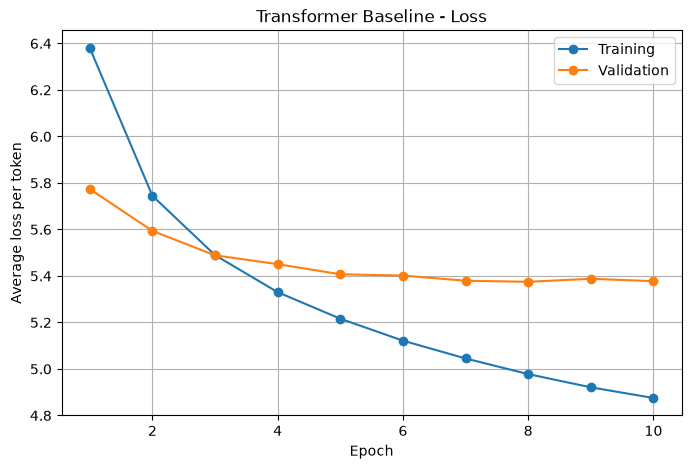

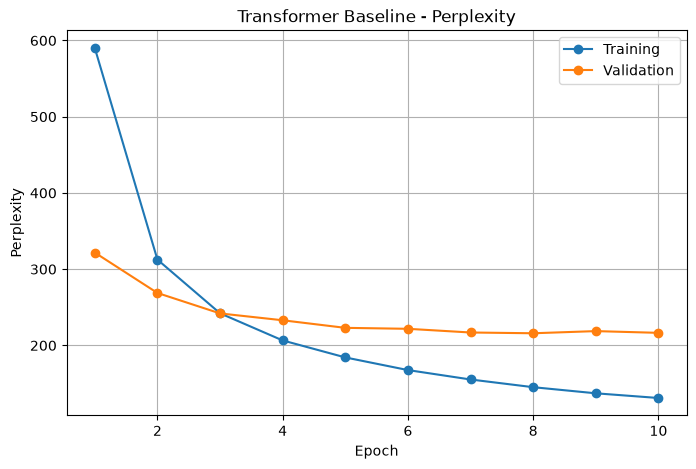

In [25]:
plot_training_history(history, "Transformer Baseline")

---

### learning rate tuning

In [26]:
LEARNING_RATES = [0.0003, 0.0005, 0.001]
TUNING_EPOCHS = 10

# same starting weights for all models
set_seed(SEED)

reference_model = AttentionLanguageModel(**MODEL_CONFIG) # first we creat a model
initial_weights = copy.deepcopy(reference_model.state_dict()) # save its initial parmeters, we do this cuz we want to compare learning rates under similar conditions
del reference_model


results = []
histories = {}


for lr in LEARNING_RATES:
    print(f"\nTesting learning rate: {lr}")

    set_seed(SEED)
    model = AttentionLanguageModel(**MODEL_CONFIG).to(device)
    model.load_state_dict(initial_weights)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    best_ppl = float("inf")
    best_epoch = None
    history = []
    model_path = MODEL_DIR/f"attention_tuning_lr_{lr}.pt"

    for epoch in range(1, TUNING_EPOCHS + 1):

        train_results = run_epoch(model, make_train_loader(SEED + epoch), criterion, optimizer)

        val_results = run_epoch(model, validation_loader, criterion)

        train_loss = train_results["loss"]
        train_ppl = train_results["perplexity"]
        val_loss = val_results["loss"]
        val_ppl = val_results["perplexity"]

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_perplexity": train_ppl,
            "validation_loss": val_loss,
            "validation_perplexity": val_ppl
        })

        print(f"Epoch {epoch}/{TUNING_EPOCHS} | "
              f"Train PPL: {train_ppl:.2f} | "
              f"Val PPL: {val_ppl:.2f}")

        if val_ppl < best_ppl:

            best_ppl = val_ppl
            best_epoch = epoch

            checkpoint = {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "model_config": MODEL_CONFIG,
                "learning_rate": lr,
                "best_validation_perplexity": best_ppl
            }

            torch.save(checkpoint, model_path)

    results.append({
        "learning_rate": lr,
        "best_epoch": best_epoch,
        "best_validation_perplexity": best_ppl,
        "checkpoint": str(model_path)
    })

    histories[str(lr)] = history

    del model, optimizer # to free memory

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


tuning_df = pd.DataFrame(results)

tuning_df = tuning_df.sort_values("best_validation_perplexity").reset_index(drop=True) # sorting it

display(tuning_df)

tuning_df.to_csv(MODEL_DIR/"attention_tuning_results.csv", index=False)

with open(MODEL_DIR/"attention_tuning_history.json", "w") as f:
    json.dump(histories, f, indent=2)


best_lr = float(tuning_df.iloc[0]["learning_rate"])
print("Best learning rate:", best_lr)


Testing learning rate: 0.0003
Epoch 1/10 | Train PPL: 734.86 | Val PPL: 396.30
Epoch 2/10 | Train PPL: 405.10 | Val PPL: 329.32
Epoch 3/10 | Train PPL: 314.53 | Val PPL: 298.10
Epoch 4/10 | Train PPL: 267.17 | Val PPL: 280.92
Epoch 5/10 | Train PPL: 237.80 | Val PPL: 268.32
Epoch 6/10 | Train PPL: 217.09 | Val PPL: 257.47
Epoch 7/10 | Train PPL: 201.73 | Val PPL: 248.07
Epoch 8/10 | Train PPL: 189.78 | Val PPL: 242.63
Epoch 9/10 | Train PPL: 179.73 | Val PPL: 237.64
Epoch 10/10 | Train PPL: 171.40 | Val PPL: 229.55

Testing learning rate: 0.0005
Epoch 1/10 | Train PPL: 660.08 | Val PPL: 359.52
Epoch 2/10 | Train PPL: 356.03 | Val PPL: 298.73
Epoch 3/10 | Train PPL: 276.24 | Val PPL: 270.64
Epoch 4/10 | Train PPL: 235.46 | Val PPL: 257.49
Epoch 5/10 | Train PPL: 209.79 | Val PPL: 243.46
Epoch 6/10 | Train PPL: 191.22 | Val PPL: 235.73
Epoch 7/10 | Train PPL: 177.55 | Val PPL: 227.83
Epoch 8/10 | Train PPL: 166.60 | Val PPL: 224.04
Epoch 9/10 | Train PPL: 157.24 | Val PPL: 219.97
Epoch 

,learning_rate,best_epoch,best_validation_perplexity,checkpoint
0,0.0010,8,215.915040,/home/gusvahaye@GU.GU.SE/Smart-Autocomplete-Sy...
1,0.0005,10,217.267293,/home/gusvahaye@GU.GU.SE/Smart-Autocomplete-Sy...
2,0.0003,10,229.549087,/home/gusvahaye@GU.GU.SE/Smart-Autocomplete-Sy...


Best learning rate: 0.001


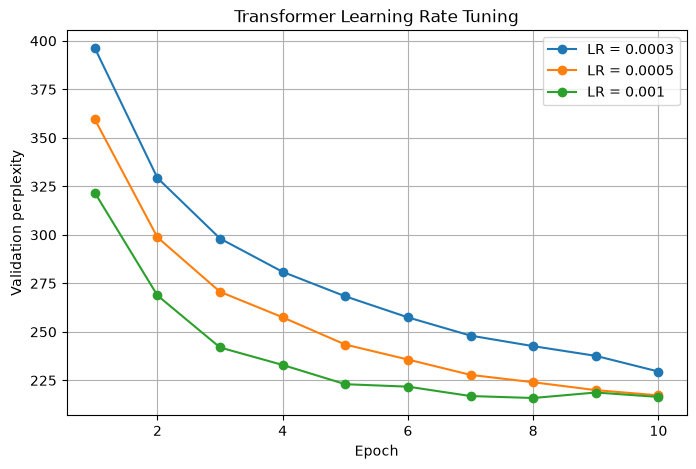

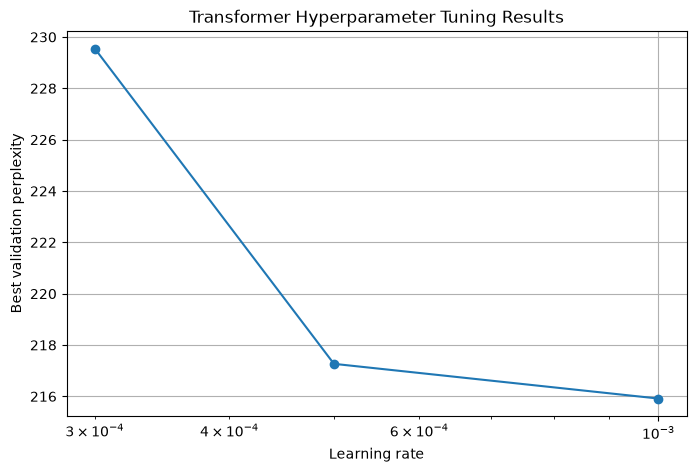

In [27]:
# Graph 1: Validation perplexity for each learning rate
plt.figure(figsize=(8, 5))
for lr in LEARNING_RATES:

    history = histories[str(lr)]

    epochs = [row["epoch"] for row in history]
    val_ppl = [row["validation_perplexity"] for row in history]

    plt.plot(epochs, val_ppl, marker="o", label=f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Validation perplexity")
plt.title("Transformer Learning Rate Tuning")
plt.legend()
plt.grid(True)
plt.show()


# Graph 2: Best perplexity for each learning rate
learning_rates = tuning_df["learning_rate"]
best_ppl = tuning_df["best_validation_perplexity"]

plt.figure(figsize=(8, 5))
plt.plot(learning_rates, best_ppl, marker="o")

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Best validation perplexity")
plt.title("Transformer Hyperparameter Tuning Results")
plt.grid(True)
plt.show()


### loading the best tuned checkpoint

In [28]:
best_path = tuning_df.iloc[0]["checkpoint"] # best saved model

checkpoint = torch.load(best_path, map_location=device, weights_only=True)

tuned_model = AttentionLanguageModel(**MODEL_CONFIG).to(device)
tuned_model.load_state_dict(checkpoint["model_state_dict"]) # trained weights
tuned_model.eval()

print("Best checkpoint:", best_path)
print("Learning rate:", checkpoint["learning_rate"])
print("Best epoch:", checkpoint["epoch"])
print("Validation perplexity:", checkpoint["best_validation_perplexity"])

Best checkpoint: /home/gusvahaye@GU.GU.SE/Smart-Autocomplete-Systems/models/attention/attention_tuning_lr_0.001.pt
Learning rate: 0.001
Best epoch: 8
Validation perplexity: 215.91504027330717


## Evaluation

In [29]:
def evaluate_attention_model(model, sequences, top_k=5, batch_size=32):

    model.eval()

    total_loss = 0
    total_predictions = 0
    unk_count = 0
    known_count = 0
    correct_top1 = 0
    correct_topk = 0

    special_ids = [bos_id, eos_id, pad_id, unk_id]

    # creating input output targets
    groups = defaultdict(list)

    for sequence in sequences:
        for i in range(1, len(sequence)): # we go through each token position
            context = sequence[max(0, i - BLOCK_SIZE):i]
            target = int(sequence[i])
            groups[len(context)].append((context, target)) # grouping examples by context length
            # cuz pyTorch usually require tensors with consisten dimensions, i could use padding like i did for lstm but here by grouping context of equal length we avoid introducing artificial left-padding that can shift the learned positional embeddings.

    # evaluating each group
    with torch.no_grad():
        for length, examples in groups.items(): # length tells us how many tokens each context contain
            for start in range(0, len(examples), batch_size):

                batch = examples[start:start + batch_size]
                inputs = torch.tensor([x for x, y in batch], dtype=torch.long, device=device)
                targets = torch.tensor([y for x, y in batch], dtype=torch.long, device=device)

                # predicting next token
                logits = model(inputs)[:, -1, :] # cux we want the prediction for the last token, we keep all the examples in the batch and then select the last token and then keep all the vocabulary scores

                # calculating perplexity loss
                log_probs = torch.log_softmax(logits, dim=-1) # logits to logorithm of probabilities

                target_log_probs = log_probs.gather(1, targets.unsqueeze(1)) # to extract the log-probability of the correct target token for each example

                total_loss -= target_log_probs.sum().item()
                total_predictions += len(batch)

                # unknown tokens
                unk_count += (targets == unk_id).sum().item()

                known_mask = torch.ones_like(targets, dtype=torch.bool) # to count known targets
                for special_id in special_ids:
                    known_mask &= targets != special_id

                known_count += known_mask.sum().item()

                # accuracy for known tokens
                if known_mask.any():

                    # scores of the known targets
                    scores = logits[known_mask].clone()
                    scores[:, special_ids] = float("-inf") # we exclud special tokens

                    k = min(top_k, scores.shape[1] - len(set(special_ids)))
                    predictions = scores.topk(k, dim=1).indices
                    actual = targets[known_mask]

                    correct_top1 += (predictions[:, 0] == actual).sum().item()
                    correct_topk += (predictions == actual.unsqueeze(1)).any(dim=1).sum().item()

    if total_predictions == 0:
        raise ValueError("No valid predictions found.")

    perplexity = math.exp(total_loss / total_predictions)

    top1_accuracy = correct_top1 / known_count if known_count else 0
    topk_accuracy = correct_topk / known_count if known_count else 0
    unk_rate = unk_count / total_predictions

    return {
        "perplexity": perplexity,
        "top1_accuracy": top1_accuracy,
        f"top{top_k}_accuracy": topk_accuracy,
        "unk_rate": unk_rate,
        "number_of_predictions": total_predictions
    }


In [30]:
# on validation and test data
validation_results = evaluate_attention_model(tuned_model, encoded_lines["validation"])
test_results = evaluate_attention_model(tuned_model, encoded_lines["test"])

print("final attention model results")
print("Learning rate:", checkpoint["learning_rate"])
print("Best epoch:", checkpoint["epoch"])
print("Vocabulary size:", vocab_size)

print(f"{'Metric':<25} {'Validation':>12} {'Test':>12}")
print("-" * 53)
for metric in validation_results:
    val, test = validation_results[metric], test_results[metric]
    if "accuracy" in metric or metric == "unk_rate":
        a, b = f"{val:.2%}", f"{test:.2%}"
    elif metric == "number_of_predictions":
        a, b = str(val), str(test)
    else:
        a, b = f"{val:.4f}", f"{test:.4f}"
    print(f"{metric:<25} {a:>12} {b:>12}")

with open(MODEL_DIR/"attention_final_metrics.json", "w") as f:
    json.dump(
        {"validation": validation_results,
         "test": test_results},
        f, indent=2)


final attention model results
Learning rate: 0.001
Best epoch: 8
Vocabulary size: 46165
Metric                      Validation         Test
-----------------------------------------------------
perplexity                    205.9724     202.3099
top1_accuracy                   21.31%       21.50%
top5_accuracy                   40.10%       40.41%
unk_rate                         5.38%        5.96%
number_of_predictions           206188       232065


---

### examples

In [31]:
 # to take a sequence of token ids and the return the ids of the model's five highest ranked next token suggestions
def get_attention_suggestion_ids(prefix_ids, model, top_k=5):
    prefix_ids = list(prefix_ids)[-BLOCK_SIZE:] # keeping only last 32 tokens
    inputs = torch.tensor([prefix_ids], dtype=torch.long, device=device)

    model.eval()
    with torch.no_grad():
   
        scores = model(inputs)[0, -1, :].clone() 
        special_ids = [bos_id, eos_id, pad_id, unk_id]
        scores[special_ids] = float("-inf") # ingore like before

        k = min(top_k, len(scores) - len(set(special_ids)))
        suggestions = scores.topk(k).indices.tolist()

    return suggestions

In [32]:
# to select random examples from the test dataset and display the models predictions
def show_test_examples(sequences, model, number_of_examples=8, seed=42):

    random.seed(seed)

    # finding valid test position
    candidates = []
    special_ids = [bos_id, eos_id, pad_id, unk_id]
    
    for sequence_index, sequence in enumerate(sequences): # we want were the correct next token is not a special token
        for position in range(3, len(sequence)): # context at least must have three tokens
            if sequence[position] not in special_ids:
                candidates.append((sequence_index, position))

    # random examples
    selected = random.sample(candidates, min(number_of_examples, len(candidates))) # selecting up to 8 exmaples without replacement

    for number, (sequence_index, position) in enumerate(selected, 1):
        sequence = sequences[sequence_index]

        prefix = sequence[:position]
        actual = sequence[position]
        
        #  model suggestions
        suggestion_ids = get_attention_suggestion_ids(prefix, model, top_k=5)

        # IDs into words
        prefix_words = [id_to_word[int(t)] for t in prefix[-8:]]
        actual_word = id_to_word[int(actual)]
        suggested_words = [id_to_word[t] for t in suggestion_ids]

        print(f"\nExample {number}")
        print("Prefix:", " ".join(prefix_words))
        print("Correct word:", actual_word)
        print("Suggestions:", ", ".join(suggested_words))
        print("Correct word in top 5:", int(actual) in suggestion_ids)

In [33]:
# 8 test examples
show_test_examples(encoded_lines["test"], tuned_model, number_of_examples=8, seed=42)



Example 1
Prefix: for the The New York Dramatic Mirror found
Correct word: the
Suggestions: it, that, the, a, him
Correct word in top 5: True

Example 2
Prefix: three chief characteristics : a <unk> hull ,
Correct word: steam
Suggestions: which, a, the, and, but
Correct word in top 5: False

Example 3
Prefix: 2013 . It peaked at number 13 in
Correct word: its
Suggestions: the, ), (, Japan, Canada
Correct word in top 5: False

Example 4
Prefix: and memorials . It also began the task
Correct word: of
Suggestions: of, ,, force, to, in
Correct word in top 5: True

Example 5
Prefix: Most Valuable Player award . <unk> was the
Correct word: first
Suggestions: first, second, third, only, most
Correct word in top 5: True

Example 6
Prefix: <unk> , Christina <unk> 's posthumous <unk> Works
Correct word: ,
Suggestions: ,, (, and, ., in
Correct word in top 5: True

Example 7
Prefix: ( 153 km / h ) and tops
Correct word: out
Suggestions: on, ., ,, (, of
Correct word in top 5: False

Example 8
Pref

## Computational Cost measurement

---

In [34]:
# counting trainable parameters
number_of_parameters = sum(parameter.numel() for parameter in tuned_model.parameters() if parameter.requires_grad)

print(f"Trainable parameters: {number_of_parameters:,}")

# measuring model size (parameters only)
model_size_mb = sum(parameter.numel() * parameter.element_size() for parameter in tuned_model.parameters()) / (1024 ** 2)

print(f"Model parameter size: {model_size_mb:.2f} MiB")


# measuring saved checkpoint size
checkpoint_size_mb = os.path.getsize(best_path) / (1024 ** 2)

print(f"Saved checkpoint size: {checkpoint_size_mb:.2f} MiB")


# collecting test contexts for inference benchmarking
rng = random.Random(42)

contexts = [
    sequence[max(0, i - BLOCK_SIZE):i]
    for sequence in encoded_lines["test"]
    for i in range(1, len(sequence))
]

# selecting 500 random contexts
contexts = rng.sample(contexts, k=min(500, len(contexts)))


# preparing the model for inference
tuned_model.eval()

# warm-up to avoid measuring initial GPU overhead
with torch.inference_mode():
    for context in contexts[:10]:
        get_attention_suggestion_ids(context, tuned_model, top_k=5)

if device.type == "cuda":
    torch.cuda.synchronize()


# measuring autocomplete inference time
start = time.perf_counter()

with torch.inference_mode():
    for context in contexts:
        get_attention_suggestion_ids(context, tuned_model, top_k=5)

if device.type == "cuda":
    torch.cuda.synchronize()

inference_time = time.perf_counter() - start

predictions_per_second = len(contexts) / inference_time

print(f"Inference time: {inference_time:.2f} seconds")
print(f"Predictions per second: {predictions_per_second:.2f}")

Trainable parameters: 12,133,717
Model parameter size: 46.29 MiB
Saved checkpoint size: 138.90 MiB
Inference time: 0.41 seconds
Predictions per second: 1219.13


---

## Same examples, test

In [35]:
# selecting the same 10 test examples for all three models
def select_test_examples(sequences, number_of_examples=10, seed=42):

    rng = random.Random(seed)
    candidates = [] # valid next-word prediction positions
    special_ids = {bos_id, eos_id, pad_id, unk_id}

    for sequence_index, sequence in enumerate(sequences):
        for target_position in range(3, len(sequence)):

            target_id = sequence[target_position]

            # skipping special-token targets
            if target_id in special_ids:
                continue

            candidates.append((sequence_index, target_position))

    # selecting 10 examples without replacement
    selected = rng.sample(candidates, k=min(number_of_examples, len(candidates)))

    return selected


selected_examples = select_test_examples(encoded_lines["test"], number_of_examples=10, seed=42)

print("Selected example positions:", selected_examples)

Selected example positions: [(1684, 131), (260, 45), (59, 95), (1955, 71), (713, 78), (641, 119), (591, 35), (336, 25), (1946, 44), (213, 121)]


In [36]:
# testing the Transformer model on the selected examples
def compare_transformer_examples(sequences, model, selected_examples):

    for example_number, (sequence_index, target_position) in enumerate(selected_examples, start=1):

        sequence = sequences[sequence_index]
        prefix_ids = sequence[:target_position]
        actual_next_id = sequence[target_position]

        # displaying the last 8 tokens
        prefix_text = " ".join(id_to_word[token_id] for token_id in prefix_ids[-8:])

        # predicting using up to 32 tokens
        suggestion_ids = get_attention_suggestion_ids(prefix_ids, model, top_k=5)

        suggestions = [id_to_word[token_id] for token_id in suggestion_ids]

        print(f"\nExample {example_number}")
        print("Prefix:", prefix_text)
        print("Correct word:", id_to_word[actual_next_id])
        print("Suggestions:", ", ".join(suggestions))
        print("Correct word in Top-5:", actual_next_id in suggestion_ids)


print("========== Transformer  ==========")
compare_transformer_examples(encoded_lines["test"], tuned_model, selected_examples)


========== Transformer  ==========

Example 1
Prefix: for the The New York Dramatic Mirror found
Correct word: the
Suggestions: it, that, the, a, him
Correct word in Top-5: True

Example 2
Prefix: three chief characteristics : a <unk> hull ,
Correct word: steam
Suggestions: which, a, the, and, but
Correct word in Top-5: False

Example 3
Prefix: 2013 . It peaked at number 13 in
Correct word: its
Suggestions: the, ), (, Japan, Canada
Correct word in Top-5: False

Example 4
Prefix: and memorials . It also began the task
Correct word: of
Suggestions: of, ,, force, to, in
Correct word in Top-5: True

Example 5
Prefix: Most Valuable Player award . <unk> was the
Correct word: first
Suggestions: first, second, third, only, most
Correct word in Top-5: True

Example 6
Prefix: <unk> , Christina <unk> 's posthumous <unk> Works
Correct word: ,
Suggestions: ,, (, and, ., in
Correct word in Top-5: True

Example 7
Prefix: ( 153 km / h ) and tops
Correct word: out
Suggestions: on, ., ,, (, of
Correct w